# Longitudinal profile — Longitudinal electromagnetic shower

This notebook validates the reusable mean-profile model implemented in `src/ams_ecal/electron_model/longitudinal.py`. It deliberately does not implement shower physics a second time.

An electromagnetic cascade begins through bremsstrahlung and pair production. Particle multiplicity initially grows, secondary energies fall toward the effective critical energy $E_c$, and ionization/absorption eventually dominate. The gamma profile below is a **phenomenological parametrization** of that cascade, not an exact first-principles QED theorem.

The model can describe two different physical quantities, called **regimes**: the *true energy deposition* in the lead/fibre composite (`deposition`), or the *signal-level* shape that a sampling calorimeter actually records (`sampling`). This notebook shows both side by side and explains how they differ.

## Mean gamma profile

With depth $t$ measured in radiation lengths $X_0$, the normalized mean energy-deposition density is

$$
f(t) = \frac{\beta (\beta t)^{\alpha-1} e^{-\beta t}}{\Gamma(\alpha)}.
$$

Its mode is

$$
T = t_{\max} = \frac{\alpha-1}{\beta}.
$$

AMS reports the detector-specific constant $\beta=0.65$ and the relation $\alpha=1+\beta T$. AMS itself publishes **no** closed-form $T(E)$: it fits $T$ shower by shower to the observed cell deposits. The mean depth used here is therefore an external choice, written in general form as

$$
T(E) = \ln(E/E_c) + \delta_{\text{regime}} + \Delta_{\text{sampling}},
$$

where $\delta_{\text{regime}}$ is a constant offset and $\Delta_{\text{sampling}}$ is a correction that is zero in the `deposition` regime. Because the AMS form $\alpha=1+\beta T$ holds for any $T$, changing $\delta$ or $\Delta$ does not break agreement with the published AMS functional form. The geometry supplies $E_c=7.6$ MeV, avoiding a duplicated material constant. Electron and positron mean profiles are identical at this level.

## Two regimes: true deposition and sampled signal

| | `deposition` | `sampling` |
|---|---|---|
| What the profile describes | true energy deposited in the lead/fibre composite | the shape of the *signal* read out from the fibres |
| Offset $\delta$ | $-0.5$, the PDG electron energy-deposition value, $t_{\max}=\ln(E/E_c)-0.5$ | $-0.812$, the Grindhammer and Peters homogeneous-medium base (arXiv:hep-ex/0001020, appendix A.1) |
| Sampling correction $\Delta$ | $0$ | negative, derived from the detector geometry (below) |

The sampling correction follows Grindhammer and Peters (appendix A.2):

$$
\Delta_{\text{sampling}} = -\left[\frac{c_F}{F_S} + c_e\,(1-\hat e)\right],
\qquad
F_S=\frac{X_{0,\mathrm{eff}}}{d_a+d_p},
\qquad
\hat e=\frac{1}{1+0.007\,(Z_p-Z_a)}.
$$

$F_S$ is the sampling frequency (radiation lengths per absorber-plus-fibre cell), $\hat e$ is the electron-to-mip response ratio, $Z_p$ is the absorber (lead) atomic number and $Z_a$ the effective atomic number of the fibre; $c_F$ and $c_e$ are the published coefficients stored in `configs/fastmc.yaml`. Physically, low-energy photons late in the cascade are absorbed preferentially in the high-$Z$ absorber, so the response to the soft tail falls with depth and the **signal maximum appears shallower** than the true energy-deposition maximum. Both terms are negative, so $\Delta_{\text{sampling}}<0$.

Which one is used where: the top-level `regime` in `configs/fastmc.yaml` selects the pair for the fast simulation, and the model's own default is `sampling`. The stochastic generator picks its fluctuation width from the same regime, because a mean from one regime and a width from the other would be incoherent. Under `sampling` the detector-sampling distortion of the shape is already applied, so a later detector-response model must not apply it a second time.

**Caveat on inputs.** The fibre's effective atomic number $Z_a=5.3$ is a project assumption that is not verified against a source; the configuration notes that the correction is weakly sensitive to it. This notebook demonstrates the arithmetic and the contrast between regimes; it does not validate either regime against Geant4 or data.

## Finite layer integration and leakage

For readout layer $l$ with finite bounds $[t_l^-, t_l^+]$,

$$
F_l = \int_{t_l^-}^{t_l^+} f(t)\,dt,
\qquad
E_l = E_{\mathrm{primary}} F_l.
$$

The 18 fractions are **not renormalized** to sum to one. The ECAL ends at $17X_0$, so $1-\sum_l F_l$ is the mean longitudinal leakage predicted by this idealized profile. SciPy's regularized incomplete gamma function evaluates the interval integrals reliably.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from ams_ecal import (
    AMSLongitudinalGammaModel,
    load_fastmc_config,
    load_geometry,
)

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

geometry = load_geometry(PROJECT_ROOT / "configs" / "geometry.yaml")
fastmc_config = load_fastmc_config(PROJECT_ROOT / "configs" / "fastmc.yaml")

REGIMES = ("deposition", "sampling")
LINE_STYLE = {"deposition": "--", "sampling": "-"}
models = {
    regime: AMSLongitudinalGammaModel(
        config=fastmc_config.longitudinal_em,
        geometry=geometry,
        regime=regime,
    )
    for regime in REGIMES
}

In [2]:
sampling_model = models["sampling"]
print(f"Effective critical energy: {sampling_model.critical_energy_mev:.2f} MeV")
print(f"AMS gamma rate beta:     {sampling_model.config.gamma_rate:.2f}")
print(f"Finite ECAL depth:       {geometry.total_depth_x0:.1f} X0")
print(f"Readout intervals:       {geometry.number_of_layers}")
print(f"Regime in configs/fastmc.yaml: {fastmc_config.regime}")
print()
print("Regime      | offset [X0] | sampling correction [X0] | total shift [X0]")
for regime, model in models.items():
    offset = model.shower_max_offset_x0
    correction = model.sampling_shower_max_correction_x0
    print(f"{regime:11s} | {offset:11.3f} | {correction:24.3f} | {offset + correction:16.3f}")
print()
print(f"Sampling frequency F_S = X0,eff/(d_a+d_p): {sampling_model.sampling_frequency:.3f}")
print(f"Electron-to-mip ratio e/mip:                {sampling_model.electron_to_mip_ratio:.4f}")

Effective critical energy: 7.60 MeV
AMS gamma rate beta:     0.65
Finite ECAL depth:       17.0 X0
Readout intervals:       18
Regime in configs/fastmc.yaml: sampling

Regime      | offset [X0] | sampling correction [X0] | total shift [X0]
deposition  |      -0.500 |                    0.000 |           -0.500
sampling    |      -0.812 |                   -0.353 |           -1.165

Sampling frequency F_S = X0,eff/(d_a+d_p): 4.897
Electron-to-mip ratio e/mip:                0.6507


## Energy dependence of the continuous profile

In each regime the profile maximum must move deeper by $\ln(10)$ radiation lengths for every decade in energy. The two regimes differ only by a constant shift: the `sampling` maximum sits a fixed distance shallower at every energy.

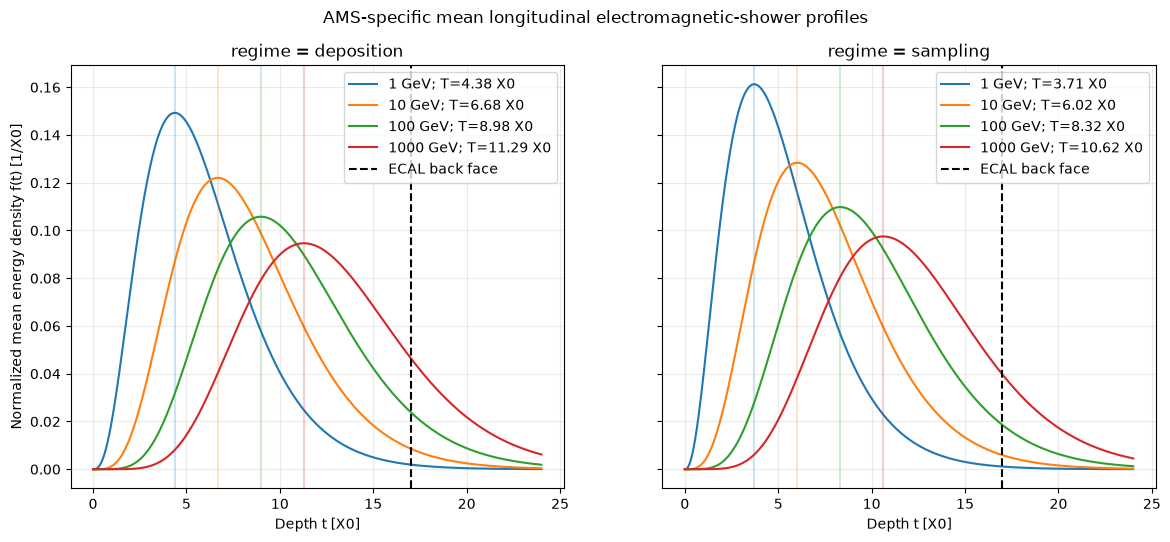

In [3]:
energies_gev = (1.0, 10.0, 100.0, 1000.0)
depths_x0 = np.linspace(0.0, 24.0, 1000)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, regime in zip(axes, REGIMES):
    model = models[regime]
    for energy_gev in energies_gev:
        energy_mev = energy_gev * 1000.0
        density = np.array([
            model.energy_density(float(depth), energy_mev)
            for depth in depths_x0
        ])
        maximum_x0 = model.shower_max_depth_x0(energy_mev)
        ax.plot(depths_x0, density, label=f"{energy_gev:g} GeV; T={maximum_x0:.2f} X0")
        ax.axvline(maximum_x0, color=ax.lines[-1].get_color(), alpha=0.22)
    ax.axvline(geometry.total_depth_x0, color="black", linestyle="--", label="ECAL back face")
    ax.set(xlabel="Depth t [X0]", title=f"regime = {regime}")
    ax.grid(alpha=0.25)
    ax.legend()
axes[0].set_ylabel("Normalized mean energy density f(t) [1/X0]")
fig.suptitle("AMS-specific mean longitudinal electromagnetic-shower profiles")
plt.show()

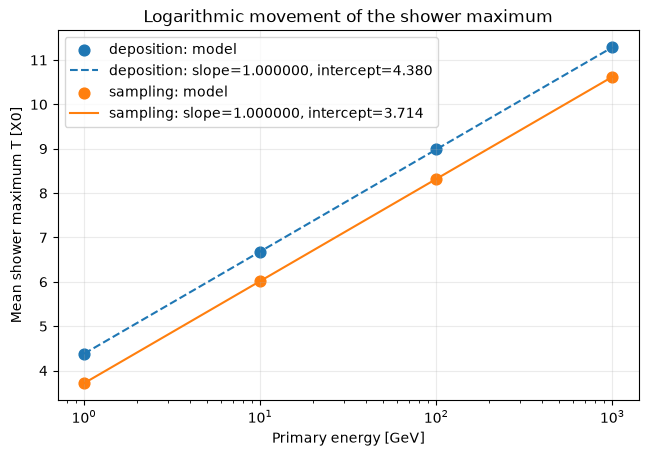

In [4]:
log_energy = np.log(np.array(energies_gev))
maxima_x0 = {
    regime: np.array([
        models[regime].shower_max_depth_x0(energy_gev * 1000.0)
        for energy_gev in energies_gev
    ])
    for regime in REGIMES
}

fig, ax = plt.subplots(figsize=(7.5, 4.8))
for regime in REGIMES:
    slope, intercept = np.polyfit(log_energy, maxima_x0[regime], deg=1)
    ax.scatter(energies_gev, maxima_x0[regime], s=60, label=f"{regime}: model")
    ax.plot(
        energies_gev,
        slope * log_energy + intercept,
        linestyle=LINE_STYLE[regime],
        label=f"{regime}: slope={slope:.6f}, intercept={intercept:.3f}",
    )
    assert np.isclose(slope, 1.0, atol=1e-12)
ax.set_xscale("log")
ax.set(
    xlabel="Primary energy [GeV]",
    ylabel="Mean shower maximum T [X0]",
    title="Logarithmic movement of the shower maximum",
)
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## Discrete 18-layer fractions

The next plot uses interval-integrated layer fractions, not midpoint samples, for both regimes at 100 GeV. Their sums remain below one whenever the continuous tail extends past the finite ECAL. The `sampling` maximum is shallower, so more of the profile falls inside the 17 $X_0$ and the leakage is smaller.

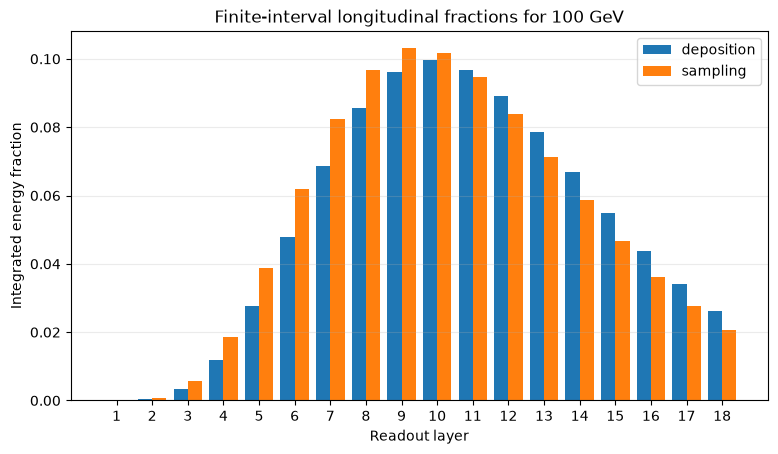

deposition  contained fraction: 0.931310   longitudinal leakage: 0.068690
sampling    contained fraction: 0.949769   longitudinal leakage: 0.050231


In [5]:
energy_gev = 100.0
layers = np.arange(1, geometry.number_of_layers + 1)
bar_width = 0.4

fig, ax = plt.subplots(figsize=(9, 4.8))
for offset, regime in zip((-bar_width / 2, bar_width / 2), REGIMES):
    fractions = np.array(models[regime].layer_energy_fractions(energy_gev * 1000.0))
    ax.bar(layers + offset, fractions, width=bar_width, label=regime)
ax.set(
    xlabel="Readout layer",
    ylabel="Integrated energy fraction",
    title=f"Finite-interval longitudinal fractions for {energy_gev:g} GeV",
)
ax.set_xticks(layers)
ax.grid(axis="y", alpha=0.25)
ax.legend()
plt.show()

for regime in REGIMES:
    model = models[regime]
    fractions = np.array(model.layer_energy_fractions(energy_gev * 1000.0))
    print(f"{regime:11s} contained fraction: {fractions.sum():.6f}   "
          f"longitudinal leakage: {model.leakage_fraction(energy_gev * 1000.0):.6f}")

In [6]:
print("Energy [GeV] |  T deposition |  T sampling | contained (dep) | contained (sam) | leakage (dep) | leakage (sam)")
for energy_gev in energies_gev:
    energy_mev = energy_gev * 1000.0
    deposition, sampling = models["deposition"], models["sampling"]
    print(
        f"{energy_gev:12g} | "
        f"{deposition.shower_max_depth_x0(energy_mev):13.3f} | "
        f"{sampling.shower_max_depth_x0(energy_mev):11.3f} | "
        f"{deposition.contained_fraction(energy_mev):15.6f} | "
        f"{sampling.contained_fraction(energy_mev):15.6f} | "
        f"{1.0 - deposition.contained_fraction(energy_mev):13.6f} | "
        f"{1.0 - sampling.contained_fraction(energy_mev):13.6f}"
    )

Energy [GeV] |  T deposition |  T sampling | contained (dep) | contained (sam) | leakage (dep) | leakage (sam)
           1 |         4.380 |       3.714 |        0.996105 |        0.997837 |      0.003895 |      0.002163
          10 |         6.682 |       6.017 |        0.979580 |        0.986666 |      0.020420 |      0.013334
         100 |         8.985 |       8.319 |        0.931310 |        0.949769 |      0.068690 |      0.050231
        1000 |        11.287 |      10.622 |        0.833109 |        0.867145 |      0.166891 |      0.132855


## Validation summary

This block establishes the deterministic mean longitudinal backbone, in both regimes:

- the density rises, reaches the analytically predicted maximum, and falls;
- the maximum moves logarithmically deeper with energy, with unit slope in $\ln E$;
- the `sampling` maximum is shallower than the `deposition` maximum by a constant: the offset difference plus the sampling correction, independent of energy;
- continuous profiles become 18 discrete values through finite-interval integration;
- electron and positron mean profiles agree;
- finite-depth leakage is preserved rather than normalized away, and is smaller under `sampling` because the maximum is shallower.

It does **not** yet generate an event. Correlated shower fluctuations belong to the stochastic generation, lateral spreading to the lateral profile, and detector response to the detector response. It also does not decide which regime is physically better: that needs a comparison with Geant4 deposition and with measured signal shapes.

In [7]:
deposition, sampling = models["deposition"], models["sampling"]
expected_shift = (
    sampling.shower_max_offset_x0
    - deposition.shower_max_offset_x0
    + sampling.sampling_shower_max_correction_x0
)

for energy_gev in energies_gev:
    energy_mev = energy_gev * 1000.0

    for regime in REGIMES:
        model = models[regime]
        electron = model.layer_energy_fractions(energy_mev, "electron")
        positron = model.layer_energy_fractions(energy_mev, "positron")
        assert electron == positron
        assert len(electron) == 18
        assert all(np.isfinite(electron))
        assert all(value >= 0.0 for value in electron)
        assert 0.0 < sum(electron) < 1.0

    shift = sampling.shower_max_depth_x0(energy_mev) - deposition.shower_max_depth_x0(energy_mev)
    assert np.isclose(shift, expected_shift, atol=1e-12)
    assert shift < 0.0
    assert sampling.contained_fraction(energy_mev) > deposition.contained_fraction(energy_mev)

assert deposition.sampling_shower_max_correction_x0 == 0.0
assert sampling.sampling_shower_max_correction_x0 < 0.0

print(f"Sampling-minus-deposition shift of the shower maximum: {expected_shift:.3f} X0 at every energy")
print("All Block-4 notebook validation checks passed for both regimes.")

Sampling-minus-deposition shift of the shower maximum: -0.665 X0 at every energy
All Block-4 notebook validation checks passed for both regimes.
